# Lista 6

Zuzanna Sosnowska

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

### Zadanie 1

**Wprowadzenie do PCA:** Wygeneruj syntetyczny zbiór danych w 3D, w którym punkty układają się w linii lub płaszczyźnie. Użyj klasy `PCA` z `scikit-learn`, aby zredukować wymiarowość do 2D. Zwizualizuj dane przed i po redukcji.

In [2]:
def generate_random_3D_data(n=1000, a=1, b=1, c=1, start=0, stop=10, std=1.0):
    x = np.linspace(start, stop, n)
    y = np.linspace(start, stop, n)
    line = a * x + b * y + c
    z = line + np.random.normal(0, std, size=n)
    return pd.DataFrame({'x': x, 'y': y, 'z': z, 'line': line})

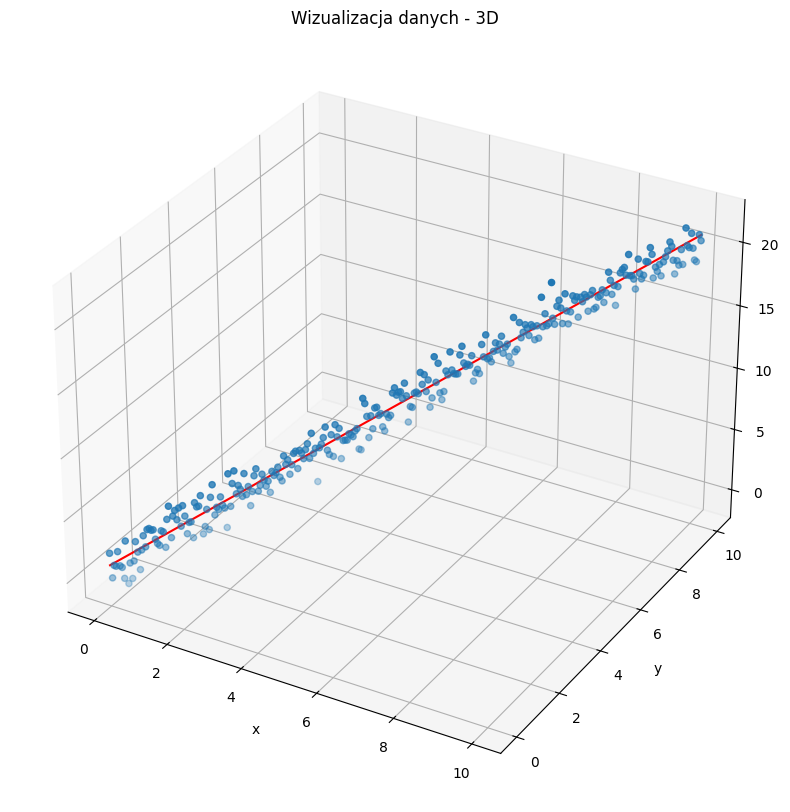

In [3]:
X = generate_random_3D_data(n=300)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')
ax.scatter(X['x'], X['y'], X['z'])
ax.plot(X['x'], X['y'], X['line'], color='red')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
plt.title('Wizualizacja danych - 3D')
plt.grid(True)
plt.show()

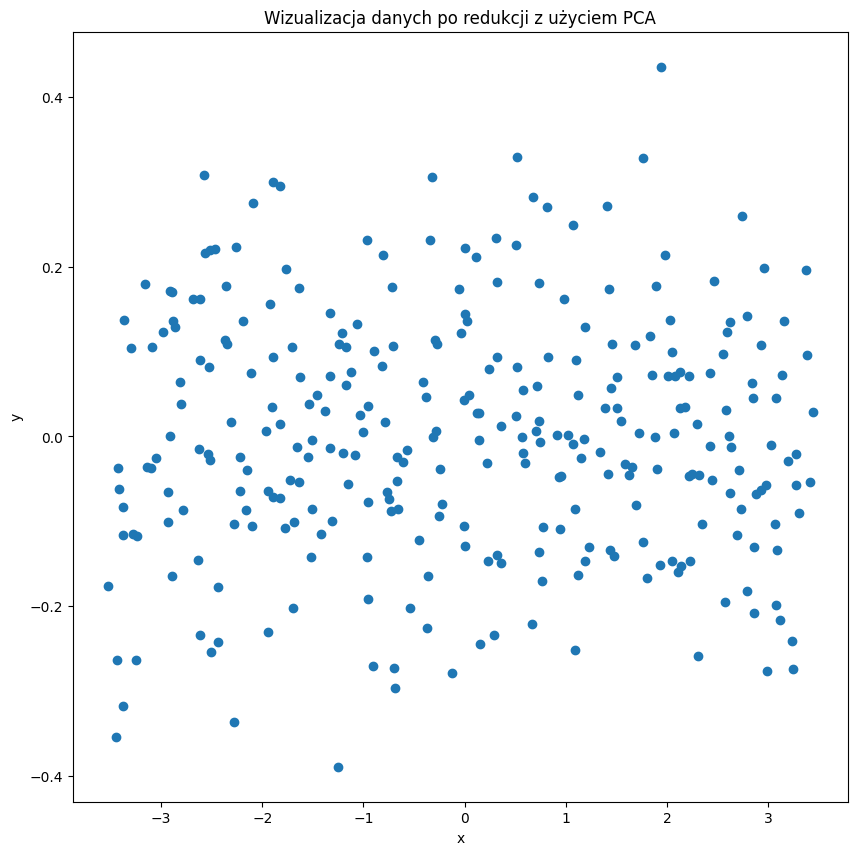

In [4]:
from sklearn.decomposition import PCA


X = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
transformed_X = pca.fit_transform(X)

plt.figure(figsize=(10, 10))
plt.scatter(transformed_X[:, 0], transformed_X[:, 1])
plt.title('Wizualizacja danych po redukcji z użyciem PCA')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

### Zadanie 2

**Analiza wariancji:** Dla zbioru danych `Iris` lub `Wine` użyj PCA i wygeneruj wykres wariancji wyjaśnionej. Zinterpretuj, ile głównych składowych należy zachować, aby wyjaśnić 95% całkowitej wariancji.

In [5]:
from sklearn.datasets import load_iris, load_wine

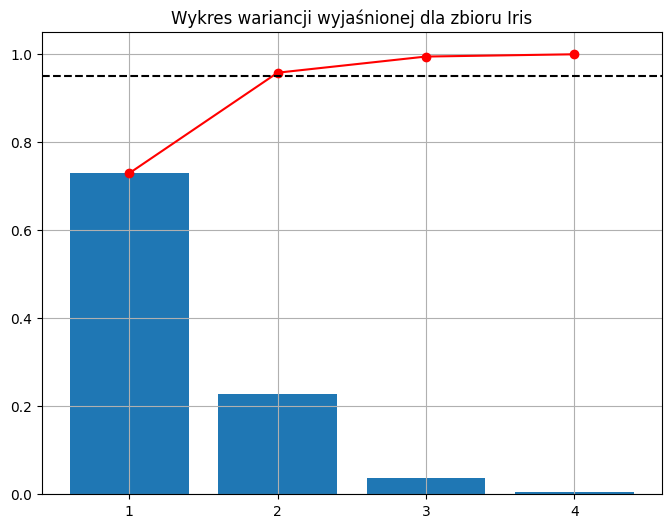

2

In [6]:
iris_df = load_iris(as_frame=True).frame

y = iris_df['target']
X = iris_df.drop('target', axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=X.shape[1])
transformed_X = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.bar(range(1, X.shape[1]+1), pca.explained_variance_ratio_)
plt.plot(range(1, X.shape[1]+1), np.cumsum(pca.explained_variance_ratio_), color='red', marker='o')
plt.axhline(y=0.95, color='black', linestyle='--')
plt.title("Wykres wariancji wyjaśnionej dla zbioru Iris")
plt.xticks(np.arange(1, X.shape[1]+1, 1))
plt.grid(True)

plt.show()

int(np.min(np.where(np.cumsum(pca.explained_variance_ratio_) > 0.95)) + 1)

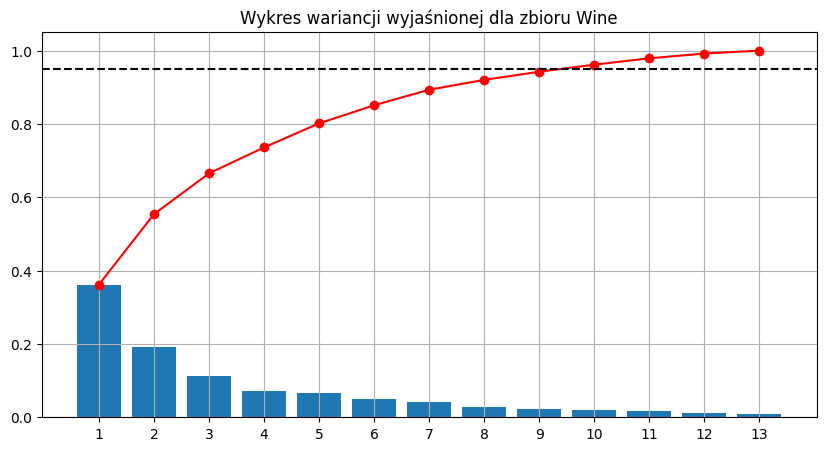

10

In [7]:
wine_df = load_wine(as_frame=True).frame

y = wine_df['target']
X = wine_df.drop('target', axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=X.shape[1])
transformed_X = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 5))

plt.bar(range(1, X.shape[1]+1), pca.explained_variance_ratio_)
plt.plot(range(1, X.shape[1]+1), np.cumsum(pca.explained_variance_ratio_), color='red', marker='o')
plt.axhline(y=0.95, color='black', linestyle='--')
plt.title("Wykres wariancji wyjaśnionej dla zbioru Wine")
plt.xticks(np.arange(1, X.shape[1]+1, 1))
plt.grid(True)

plt.show()

int(np.min(np.where(np.cumsum(pca.explained_variance_ratio_) > 0.95)) + 1)

### Zadanie 3

**Wizualizacja wielowymiarowych danych:** Zastosuj PCA do zbioru danych `Iris` lub `Wine`, redukując go do 2 głównych składowych. Stwórz wykres punktowy w 2D, kolorując punkty według ich klasy. Wyjaśnij, czy PCA jest skuteczną metodą do wizualizacji w tym przypadku.

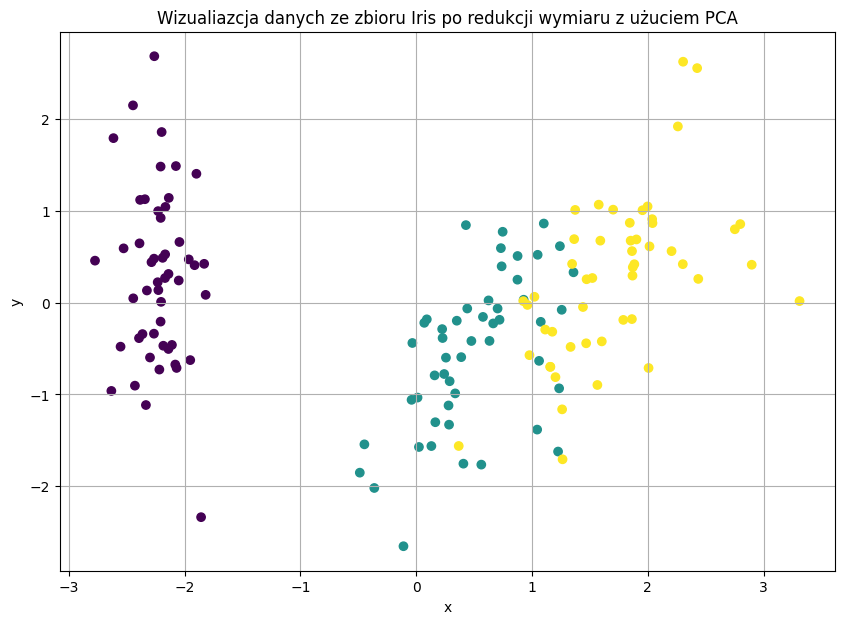

In [8]:
y = iris_df['target']
X = iris_df.drop('target', axis=1)

X = StandardScaler().fit_transform(X)

transformed_X = PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(10, 7))
plt.scatter(transformed_X[:, 0], transformed_X[:, 1], c=y)
plt.title("Wizualiazcja danych ze zbioru Iris po redukcji wymiaru z użuciem PCA")
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

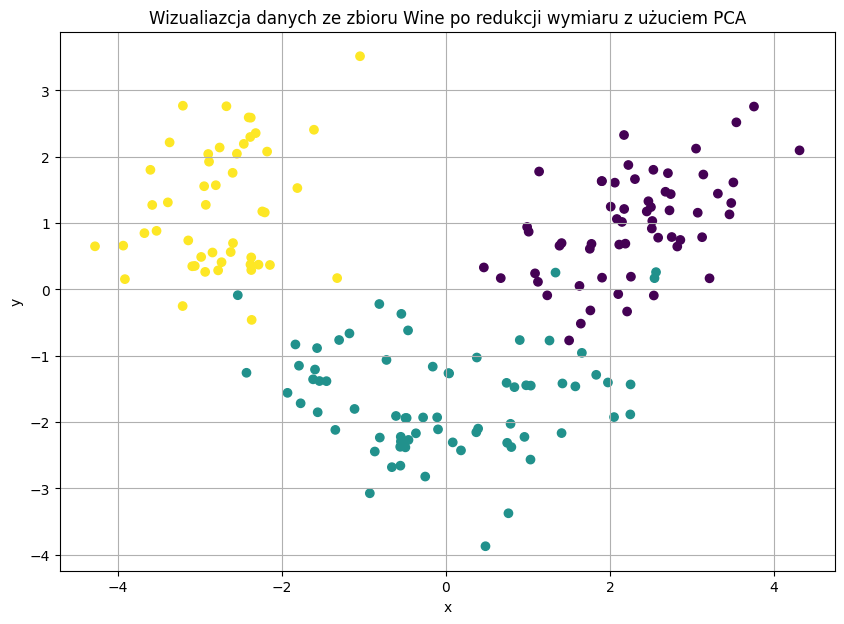

In [9]:
y = wine_df['target']
X = wine_df.drop('target', axis=1)

X = StandardScaler().fit_transform(X)
transformed_X = PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(10, 7))
plt.scatter(transformed_X[:, 0], transformed_X[:, 1], c=y)
plt.title("Wizualiazcja danych ze zbioru Wine po redukcji wymiaru z użuciem PCA")
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

### Zadanie 4

**PCA jako pre-processing:** Wytrenuj model klasyfikacyjny (np. Regresję Logistyczną lub SVM) na danych `Wine` bez redukcji wymiarowości. Następnie, zastosuj PCA, redukując dane do 2 głównych składowych, i ponownie wytrenuj ten sam model. Porównaj dokładność i czas treningu w obu przypadkach.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

In [11]:
y = wine_df['target']
X = wine_df.drop('target', axis=1)
X = StandardScaler().fit_transform(X)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_no_pca = Pipeline([
    ("clf", LogisticRegression(max_iter=2000, random_state=42))
])

pipe_pca2 = Pipeline([
    ("pca", PCA(n_components=2, random_state=42)),
    ("clf", LogisticRegression(max_iter=2000, random_state=42))
])

def run_cv(pipe, X, y, cv):
    res = cross_validate(pipe, X, y, cv=cv, scoring="accuracy", return_train_score=False, n_jobs=1)
    df = pd.DataFrame({
        "test score": res["test_score"],
        "fit time": res["fit_time"],
        "score time": res["score_time"]
    })
    summary = {
        "mean test score": np.mean(res["test_score"]),
        "std test score": np.std(res["test_score"], ddof=1),
        "mean fit time": np.mean(res["fit_time"]),
        "std fit time": np.std(res["fit_time"], ddof=1)
    }
    return df, summary

df_no_pca, summary_no_pca = run_cv(pipe_no_pca, X, y, cv)
df_pca2, summary_pca2 = run_cv(pipe_pca2, X, y, cv)

summary_table = pd.DataFrame(
    {
        "mean test accuracy": [summary_no_pca["mean test score"], summary_pca2["mean test score"]],
        "std test accuracy": [summary_no_pca["std test score"], summary_pca2["std test score"]],
        "mean fit time": [summary_no_pca["mean fit time"], summary_pca2["mean fit time"]],
        "std fit time": [summary_no_pca["std fit time"], summary_pca2["std fit time"]]
    },
    index = ["No PCA", "PCA"]
)

summary_table

,mean test accuracy,std test accuracy,mean fit time,std fit time
No PCA,0.983333,0.015215,0.002841,0.003208
PCA,0.955238,0.024581,0.001781,0.000340


In [12]:
y = wine_df['target']
X = wine_df.drop('target', axis=1)
X = StandardScaler().fit_transform(X)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_no_pca = Pipeline([
    ("clf", SVC(random_state=42))
])

pipe_pca2 = Pipeline([
    ("pca", PCA(n_components=2, random_state=42)),
    ("clf", SVC(random_state=42))
])

def run_cv(pipe, X, y, cv):
    res = cross_validate(pipe, X, y, cv=cv, scoring="accuracy", return_train_score=False, n_jobs=1)
    df = pd.DataFrame({
        "test score": res["test_score"],
        "fit time": res["fit_time"],
        "score time": res["score_time"]
    })
    summary = {
        "mean test score": np.mean(res["test_score"]),
        "std test score": np.std(res["test_score"], ddof=1),
        "mean fit time": np.mean(res["fit_time"]),
        "std fit time": np.std(res["fit_time"], ddof=1)
    }
    return df, summary

df_no_pca, summary_no_pca = run_cv(pipe_no_pca, X, y, cv)
df_pca2, summary_pca2 = run_cv(pipe_pca2, X, y, cv)

summary_table = pd.DataFrame(
    {
        "mean test accuracy": [summary_no_pca["mean test score"], summary_pca2["mean test score"]],
        "std test accuracy": [summary_no_pca["std test score"], summary_pca2["std test score"]],
        "mean fit time": [summary_no_pca["mean fit time"], summary_pca2["mean fit time"]],
        "std fit time": [summary_no_pca["std fit time"], summary_pca2["std fit time"]]
    },
    index = ["No PCA", "PCA"]
)

summary_table

,mean test accuracy,std test accuracy,mean fit time,std fit time
No PCA,0.983333,0.024845,0.001144,0.000178
PCA,0.960794,0.014928,0.001024,0.000107


### Zadanie 5

**Liniowa Analiza Dyskryminacyjna (LDA):** Wytrenuj model LDA (`LinearDiscriminantAnalysis` z `scikit-learn`) na zbiorze danych `Wine`. Zredukuj dane do 2 wymiarów i zwizualizuj je. Porównaj wyniki z wizualizacją uzyskaną za pomocą PCA i omów różnice w podejściu.

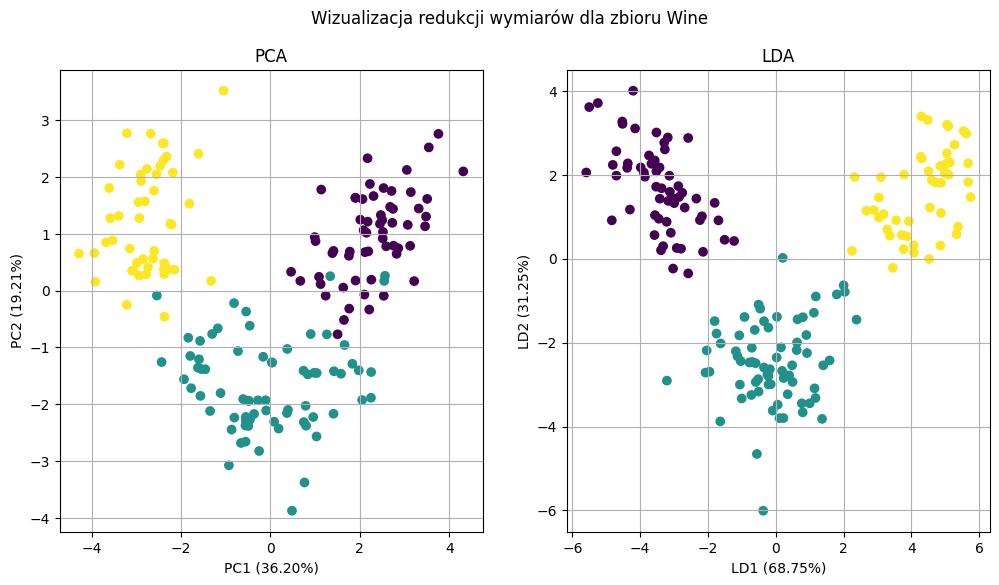

In [13]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


y = wine_df['target']
X = wine_df.drop('target', axis=1)
X = StandardScaler().fit_transform(X)

lda = LinearDiscriminantAnalysis(n_components=2)
pca = PCA(n_components=2)

X_lda = lda.fit_transform(X, y)
X_pca = pca.fit_transform(X)


fig, ax = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle('Wizualizacja redukcji wymiarów dla zbioru Wine')

ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y)
ax[0].set_title("PCA")
ax[0].grid(True)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')

ax[1].scatter(X_lda[:, 0], X_lda[:, 1], c=y)
ax[1].set_title("LDA")
ax[1].grid(True)
ax[1].set_xlabel(f'LD1 ({lda.explained_variance_ratio_[0]:.2%})')
ax[1].set_ylabel(f'LD2 ({lda.explained_variance_ratio_[1]:.2%})')

plt.show()

### Zadanie 6

**Zastosowanie na danych rzeczywistych:** Wczytaj zbiór danych do rozpoznawania twarzy (`LFW- Labeled Faces in the Wild`, dostępny w `scikit-learn`). Zastosuj PCA, aby zredukować wymiarowość obrazów. Wyświetl oryginalne obrazy i ich zrekonstruowane wersje po redukcji i dekompresji.

In [18]:
from sklearn.datasets import fetch_lfw_people


lfw_people = fetch_lfw_people()

X, y = lfw_people.data, lfw_people.target

print("Liczba rekordów i liczba wymiarów:", X.shape)

names = lfw_people.target_names

pca = PCA(n_components=X.shape[1])
X_pca = pca.fit_transform(X)

for i, element in enumerate(np.cumsum(pca.explained_variance_ratio_)):
    if element > 0.97:
        optimal_n_components = i
        print("Optymalna liczba komponentów:", i)
        break

Liczba rekordów i liczba wymiarów: (7962, 2914)
Optymalna liczba komponentów: 313


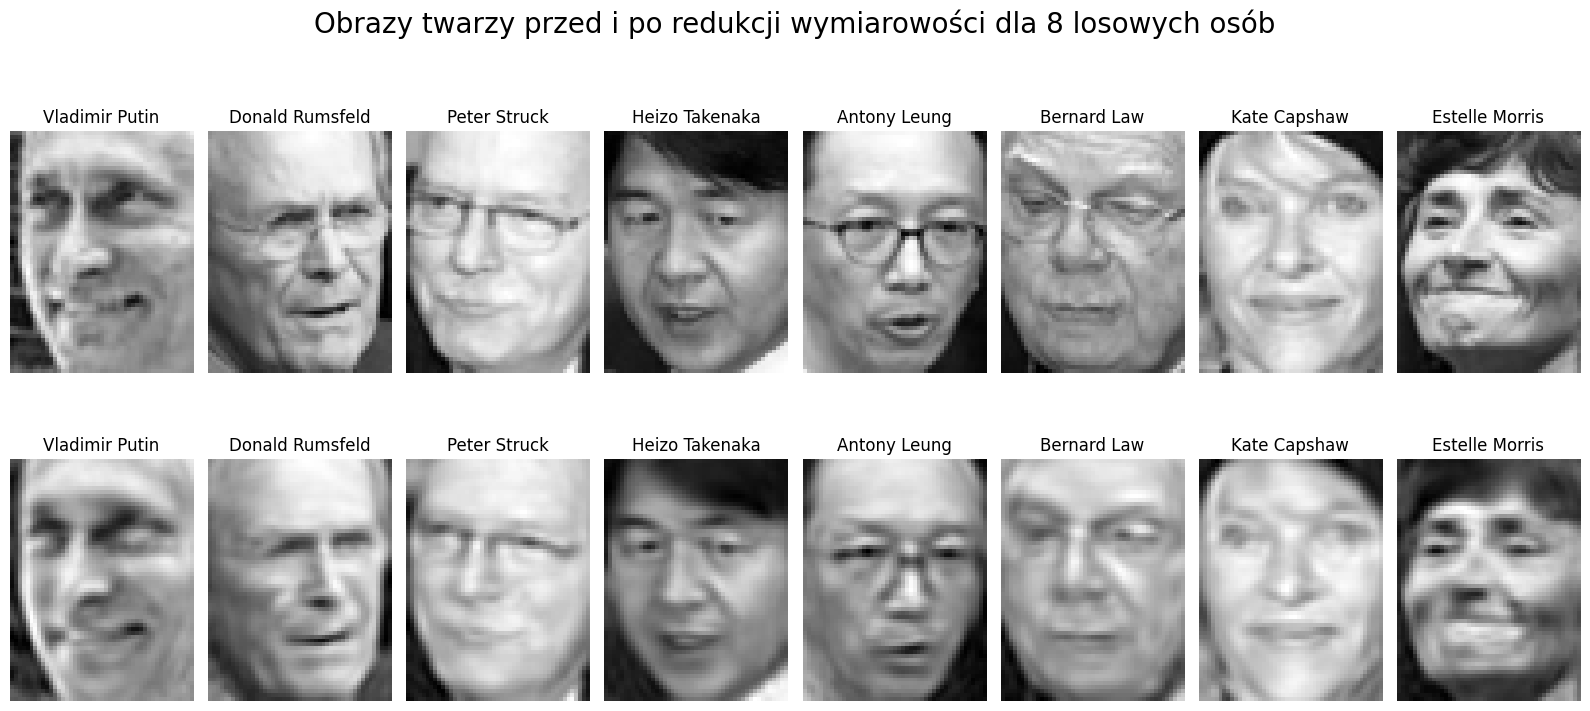

In [19]:
pca = PCA(n_components=optimal_n_components)
X_pca = pca.fit_transform(X)
X_reconstructed = pca.inverse_transform(X_pca)

h, w = lfw_people.images.shape[1], lfw_people.images.shape[2]

fig, ax = plt.subplots(2, 8, figsize=(16, 8))

fig.suptitle("Obrazy twarzy przed i po redukcji wymiarowości dla 8 losowych osób", size=20)

for i, record_number in enumerate(np.random.randint(0, y.shape, 8)):
    ax[0, i].imshow(X[record_number].reshape(h, w), cmap='gray')
    ax[0, i].set_title(names[y[record_number]])
    ax[0, i].axis("off")

    ax[1, i].imshow(X_reconstructed[record_number].reshape(h, w), cmap='gray')
    ax[1, i].set_title(names[y[record_number]])
    ax[1, i].axis("off")

plt.tight_layout()
plt.show()